In [3]:
#Import modules
%matplotlib inline
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import re

In [ ]:
#Oppgave 1: Det er 5000 rader og 12 kolonner.
Grc_df = pd.read_csv('Grocery_dataset.csv')

print(Grc_df.shape)
Grc_df.head(10)

(5000, 12)


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.300,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.920,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.500,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.200,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.930,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052
5,FDP36,10.395,Regular,0.000000,Baking Goods,51.4008,OUT018,2009,Medium,Tier 3,Supermarket Type2,556.6088
6,FDO10,13.650,Regular,0.012741,Snack Foods,57.6588,OUT013,1987,High,Tier 3,Supermarket Type1,343.5528
7,FDP10,NaN,Low Fat,0.127470,Snack Foods,107.7622,OUT027,1985,Medium,Tier 3,Supermarket Type3,4022.7636
8,FDH17,16.200,Regular,0.016687,Frozen Foods,96.9726,OUT045,2002,NaN,Tier 2,Supermarket Type1,1076.5986
9,FDU28,19.200,Regular,0.094450,Frozen Foods,187.8214,OUT017,2007,NaN,Tier 2,Supermarket Type1,4710.5350


In [8]:
Grc_df.tail(10)

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
4990,FDE46,18.60,Low Fat,0.015859,Snack Foods,152.9366,OUT017,2007,NaN,Tier 2,Supermarket Type1,453.4098
4991,NCQ53,17.60,Low Fat,0.018905,Health and Hygiene,234.6590,OUT046,1997,Small,Tier 1,Supermarket Type1,8508.9240
4992,NCN42,20.25,Low Fat,0.014281,Household,148.0418,OUT018,2009,Medium,Tier 3,Supermarket Type2,1177.1344
4993,DRH11,5.98,Low Fat,0.075675,Hard Drinks,53.3614,OUT049,1999,Medium,Tier 1,Supermarket Type1,331.5684
4994,NCI42,18.75,Low Fat,0.010382,Household,207.8954,OUT049,1999,Medium,Tier 1,Supermarket Type1,2292.3494
4995,FDT07,5.82,Regular,0.077476,Fruits and Vegetables,255.3330,OUT045,2002,NaN,Tier 2,Supermarket Type1,4870.3270
4996,DRL60,8.52,Low Fat,0.027059,Soft Drinks,153.3682,OUT046,1997,Small,Tier 1,Supermarket Type1,914.8092
4997,FDG20,15.50,Regular,0.126200,Fruits and Vegetables,178.4028,OUT018,2009,Medium,Tier 3,Supermarket Type2,1239.7196
4998,FDF56,16.70,Regular,0.119462,Fruits and Vegetables,182.7976,OUT046,1997,Small,Tier 1,Supermarket Type1,1810.9760
4999,FDV33,9.60,Regular,0.027455,Snack Foods,258.1304,OUT018,2009,Medium,Tier 3,Supermarket Type2,2324.9736


In [9]:
Grc_df.isna().sum()

Item_Identifier                 0
Item_Weight                   818
Item_Fat_Content                0
Item_Visibility                 0
Item_Type                       0
Item_MRP                        0
Outlet_Identifier               0
Outlet_Establishment_Year       0
Outlet_Size                  1439
Outlet_Location_Type            0
Outlet_Type                     0
Item_Outlet_Sales               0
dtype: int64

In [ ]:
Grc_df["Item_Weight"] = Grc_df["Item_Weight"].fillna(
    Grc_df["Item_Weight"].median()
)

Grc_df["Outlet_Size"] = Grc_df["Outlet_Size"].fillna(
    Grc_df["Outlet_Size"].mode()[0]
)

Grc_df.isna().sum()

#Oppgave 2: Det fantes null-vedier i Item_Weight og Outlet_Size. Vi brukte median for Item_Weight og typetall (verdi) for Outlet_Size.

Item_Identifier              0
Item_Weight                  0
Item_Fat_Content             0
Item_Visibility              0
Item_Type                    0
Item_MRP                     0
Outlet_Identifier            0
Outlet_Establishment_Year    0
Outlet_Size                  0
Outlet_Location_Type         0
Outlet_Type                  0
Item_Outlet_Sales            0
dtype: int64

In [ ]:
#Oppgave 3: Outlet_Size har 3 unike verdier, derav High, Medium og Small. Det er flest "Medium" outlets, deretter "Small" og til slutt "High".
Grc_df["Outlet_Size"].nunique()

3

In [14]:
Grc_df["Outlet_Size"].value_counts()

Outlet_Size
Medium    3044
Small     1398
High       558
Name: count, dtype: int64

In [ ]:
#Oppgave 4: Problemet er at det finnes duplikate kategorier. Lavt fettinhold kalles "LF", "low fat". Regular forkortes innimellom til "reg".
Grc_df["Item_Fat_Content"].value_counts()

Item_Fat_Content
Low Fat    3008
Regular    1679
LF          183
reg          68
low fat      62
Name: count, dtype: int64

In [19]:
Grc_df["Item_Fat_Content"] = Grc_df["Item_Fat_Content"].replace({
    "LF": "Low Fat",
    "low fat": "Low Fat",
    "reg": "Regular"
})

Grc_df["Item_Fat_Content"].value_counts()

Item_Fat_Content
Low Fat    3253
Regular    1747
Name: count, dtype: int64

In [20]:
#Oppgave 5: Lage ny tabell uten Index verdi 0 (Item_Identifier) og 6 (Outlet_Identifier).

Grc_new_df = Grc_df.drop(
    Grc_df.columns[[0, 6]],
    axis=1
)

Grc_new_df.head()

,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,9.30,Low Fat,0.016047,Dairy,249.8092,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,5.92,Regular,0.019278,Soft Drinks,48.2692,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,17.50,Low Fat,0.016760,Meat,141.6180,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,1998,Medium,Tier 3,Grocery Store,732.3800
4,8.93,Low Fat,0.000000,Household,53.8614,1987,High,Tier 3,Supermarket Type1,994.7052


In [22]:
Grc_new_df.columns

Index(['Item_Weight', 'Item_Fat_Content', 'Item_Visibility', 'Item_Type',
       'Item_MRP', 'Outlet_Establishment_Year', 'Outlet_Size',
       'Outlet_Location_Type', 'Outlet_Type', 'Item_Outlet_Sales'],
      dtype='str')

In [ ]:
#Oppgave 6

Grc_new_df["Outlet_Type"].unique()

<StringArray>
['Supermarket Type1', 'Supermarket Type2', 'Grocery Store',
 'Supermarket Type3']
Length: 4, dtype: str

In [24]:
SupType_1 = Grc_new_df[
    Grc_new_df["Outlet_Type"] == "Supermarket Type1"
]

SupType_2 = Grc_new_df[
    Grc_new_df["Outlet_Type"] == "Supermarket Type2"
]

print(SupType_1.shape)
print(SupType_2.shape)

(3328, 10)
(526, 10)


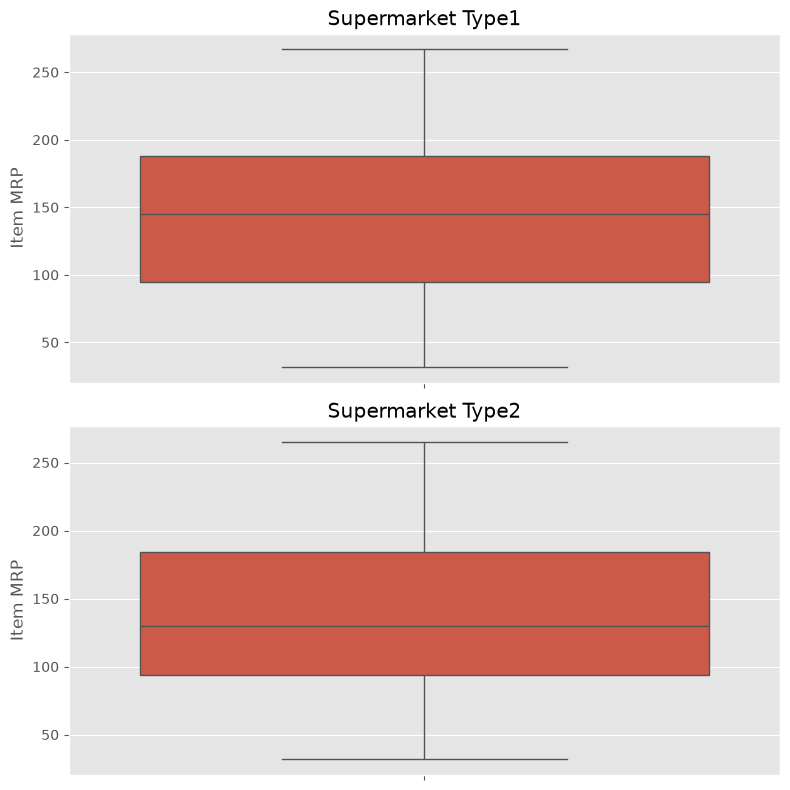

In [ ]:
#Oppgave 7: Varene ligger innenfor whiskersene på boksplottet. Dermed er det ingen verdier som er tydelige uteliggere

plt.style.use("ggplot")

fig, axes = plt.subplots(2, 1, figsize=(8, 8))

sns.boxplot(
    y=SupType_1["Item_MRP"],
    ax=axes[0]
)
axes[0].set_title("Supermarket Type1")
axes[0].set_ylabel("Item MRP")

sns.boxplot(
    y=SupType_2["Item_MRP"],
    ax=axes[1]
)
axes[1].set_title("Supermarket Type2")
axes[1].set_ylabel("Item MRP")

plt.tight_layout()
plt.show()

In [26]:
print("Supermarket Type1 median:", SupType_1["Item_MRP"].median())
print("Supermarket Type2 median:", SupType_2["Item_MRP"].median())

Supermarket Type1 median: 144.7457
Supermarket Type2 median: 130.18099999999998


In [ ]:
#Oppgave 8

Grc_Concat_df = pd.concat(
    [SupType_1, SupType_2],
    ignore_index=True
)

Grc_Concat_df = Grc_Concat_df.sort_values(
    by="Item_Outlet_Sales",
    ascending=True
)

Grc_Concat_df.head(1)

,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
1582,20.5,Low Fat,0.143164,Household,34.919,1987,High,Tier 3,Supermarket Type1,73.238


In [ ]:
#Oppgave 8: Butikken om selger minst er av Outlet_Location_Type "Tier 3".
Grc_Concat_df.iloc[0]["Outlet_Location_Type"]

'Tier 3'

In [ ]:
#Oppgave 9: Vi kjørte koden to ganger og fikk en feilmelding andre gangen.
Grc_Concat_df = Grc_Concat_df.set_index(
    ["Outlet_Size", "Outlet_Location_Type"]
)

KeyError: "None of ['Outlet_Size', 'Outlet_Location_Type'] are in the columns"

In [34]:
Grc_Concat_df.index.names

FrozenList(['Outlet_Size', 'Outlet_Location_Type'])

In [35]:
#Oppgave 10

Grc_Concat_df["Weight_Bucket"] = pd.cut(
    Grc_Concat_df["Item_Weight"],
    bins=10
)

Weight_summary = Grc_Concat_df.groupby(
    "Weight_Bucket",
    observed=False
)["Item_Weight"].agg(
    ["mean", "min", "max", "count"]
)

Weight_summary

,mean,min,max,count
Weight_Bucket,,,,
"(4.538, 6.234]",5.623814,4.555,6.215,253
"(6.234, 7.914]",7.121807,6.235,7.905,476
"(7.914, 9.594]",8.761867,7.930,9.500,450
"(9.594, 11.273]",10.344917,9.600,11.150,362
"(11.273, 12.952]",12.081635,11.300,12.850,419
"(12.952, 14.632]",13.716193,13.000,14.600,352
"(14.632, 16.312]",15.495976,14.650,16.250,410
"(16.312, 17.991]",17.172672,16.350,17.850,408
"(17.991, 19.671]",18.838005,18.000,19.600,396
